# Домашняя работа 1. Проверка корректности A/B-эксперимента

**Задача:** по данным эксперимента проверить корректность дизайна и данных, найти скрытые проблемы и предложить способы их исправления.

**Колонки данных:**
- `user_id` - идентификатор пользователя;
- `variant` - группа (`control` или `test`);
- `converted` - совершил ли пользователь целевое действие (1/0), первичная метрика;
- `error_flag` - была ли ошибка при загрузке страницы (1/0), guardrail-метрика;
- `pre_activity` - число действий пользователя за неделю до эксперимента (ковариата);
- `date` - дата события.

**Ожидаемый дизайн:** группы 50/50, рандомизация не зависит от `pre_activity`, истинного эффекта на конверсию нет.

**План:**
1. Генерация данных.
2. Базовая информация о группах.
3. Проверка SRM (хи-квадрат).
4. Проверка баланса ковариаты `pre_activity`.
5. Анализ guardrail-метрики `error_flag`.
6. Решение о валидности эксперимента.
7. Дополнительные проверки (даты, связь конверсии с активностью).
8. Бонус: исправление дисбаланса по `pre_activity` и анализ конверсии после коррекции.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from statsmodels.stats.proportion import proportions_ztest, proportion_confint
import statsmodels.api as sm

sns.set_style('whitegrid')
ALPHA = 0.05

## 1. Генерация данных

Код генерации взят из условия. Внесённые изменения:
- seed был один раз сгенерирован случайно (`np.random.randint(5000000)`) и зафиксирован, чтобы при перезапуске ноутбука получался тот же файл и выводы совпадали с цифрами. При первом запуске выпала маленькая выборка (около 1000 пользователей), на которой удвоение частоты ошибок не обнаруживается статистически, поэтому seed был перегенерирован (условие разрешает менять параметры генерации для улучшения данных);
- исправлена опечатка в создании датафрейма (`dates}]` заменено на `dates})`).

In [2]:
# seed сгенерирован один раз случайно и зафиксирован
MY_SEED = 3343644
np.random.seed(MY_SEED)

# число участников эксперимента
n_users = np.random.randint(1000, 10000, size=1)[0]

# шаг 1: ковариата pre_activity
pre_activity = np.random.exponential(scale=10, size=n_users).astype(int)

# шаг 2: нарушение 1, SRM (40/60)
variant = np.random.choice(['control', 'test'], size=n_users, p=[0.4, 0.6])

# шаг 3: нарушение 2, назначение в группу зависит от pre_activity
prob_test = 0.4 + 0.3 * (pre_activity / pre_activity.max())
variant2 = np.where(np.random.random(n_users) < prob_test, 'test', 'control')

# итоговое назначение берём через variant2 (confounder)
variant = variant2

# нарушение 3: в тесте ошибки встречаются в 2 раза чаще
error_flag = np.zeros(n_users)
error_flag[variant == 'control'] = np.random.binomial(1, 0.01, sum(variant == 'control'))
error_flag[variant == 'test'] = np.random.binomial(1, 0.02, sum(variant == 'test'))

# конверсия не зависит от варианта, но зависит от pre_activity
conversion_prob = 0.05 + 0.01 * (pre_activity / pre_activity.max())
converted = np.random.binomial(1, conversion_prob, n_users)

# шаг 4: даты за 14 дней
start_date = pd.Timestamp('2026-05-01')
dates = [start_date + pd.Timedelta(days=np.random.randint(0, 14)) for _ in range(n_users)]

df = pd.DataFrame({
    'user_id': range(n_users),
    'variant': variant,
    'converted': converted,
    'error_flag': error_flag,
    'pre_activity': pre_activity,
    'date': dates})

df.to_csv('experiment_data.csv', index=False)
print('Seed:', MY_SEED, ' пользователей:', n_users)
print('Данные сохранены в experiment_data.csv')

Seed: 3343644  пользователей: 8916
Данные сохранены в experiment_data.csv


## 2. Загрузка и базовая информация

In [3]:
df = pd.read_csv('experiment_data.csv', parse_dates=['date'])

print('Размер:', df.shape)
print('Пропусков:', df.isna().sum().sum())
print('Дубликатов user_id:', df['user_id'].duplicated().sum())
print('Период:', df['date'].min().date(), '-', df['date'].max().date())
df.head()

Размер: (8916, 6)
Пропусков: 0
Дубликатов user_id: 0
Период: 2026-05-01 - 2026-05-14


,user_id,variant,converted,error_flag,pre_activity,date
0,0,control,0,0.0,5,2026-05-08
1,1,test,0,0.0,2,2026-05-07
2,2,test,0,0.0,3,2026-05-06
3,3,test,0,0.0,19,2026-05-07
4,4,test,0,0.0,24,2026-05-14


In [4]:
# размеры групп, средняя конверсия и частота ошибок
summary = df.groupby('variant').agg(
    users=('user_id', 'count'),
    conversion=('converted', 'mean'),
    error_rate=('error_flag', 'mean'),
    pre_activity_mean=('pre_activity', 'mean'),
    pre_activity_median=('pre_activity', 'median'),
)
summary['share'] = summary['users'] / summary['users'].sum()
summary.round(4)

,users,conversion,error_rate,pre_activity_mean,pre_activity_median,share
variant,,,,,,
control,5056,0.0481,0.0113,8.9895,6.0,0.5671
test,3860,0.0528,0.0210,10.6759,7.0,0.4329


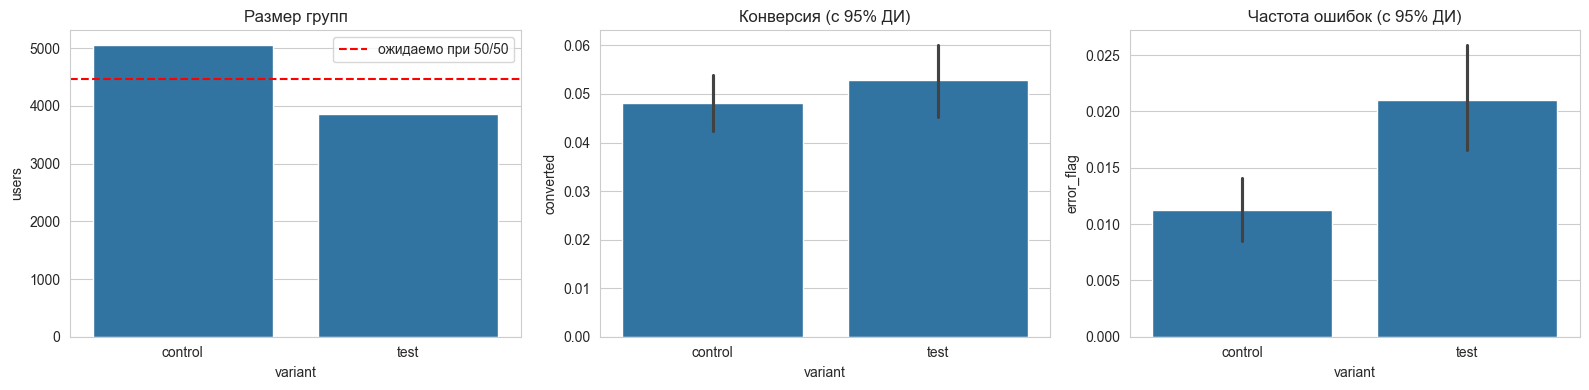

In [5]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))

sns.barplot(x=summary.index, y=summary['users'], ax=axes[0])
axes[0].axhline(len(df) / 2, color='r', linestyle='--', label='ожидаемо при 50/50')
axes[0].set_title('Размер групп')
axes[0].legend()

sns.barplot(data=df, x='variant', y='converted', ax=axes[1])
axes[1].set_title('Конверсия (с 95% ДИ)')

sns.barplot(data=df, x='variant', y='error_flag', ax=axes[2])
axes[2].set_title('Частота ошибок (с 95% ДИ)')

plt.tight_layout()
plt.show()

## 3. Проверка SRM (Sample Ratio Mismatch)

Проверяем, соответствует ли фактическое соотношение групп ожидаемому 50/50, с помощью хи-квадрат теста согласия.

In [6]:
warnings_list = []

observed = df['variant'].value_counts().reindex(['control', 'test']).values
expected = [len(df) / 2, len(df) / 2]

chi2, p_srm = stats.chisquare(observed, f_exp=expected)

print('Наблюдаемые размеры (control, test):', observed)
print('Ожидаемые размеры:', expected)
print('Доля test:', round(observed[1] / observed.sum(), 4))
print(f'Хи-квадрат = {chi2:.2f}, p-value = {p_srm:.2e}')

if p_srm < ALPHA:
    print('ПРЕДУПРЕЖДЕНИЕ: SRM обнаружен')
    warnings_list.append('SRM')
else:
    print('SRM не обнаружен')

Наблюдаемые размеры (control, test): [5056 3860]
Ожидаемые размеры: [4458.0, 4458.0]
Доля test: 0.4329
Хи-квадрат = 160.43, p-value = 9.10e-37
ПРЕДУПРЕЖДЕНИЕ: SRM обнаружен


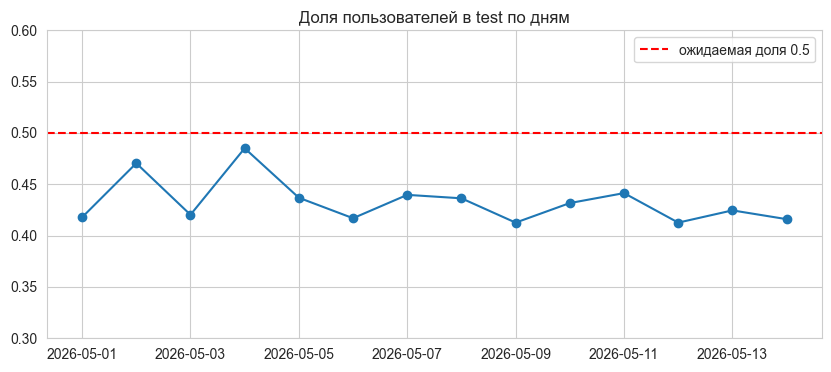

variant     control  test  test_share  p_value
date                                          
2026-05-01      386   277      0.4178   0.0000
2026-05-02      323   287      0.4705   0.1450
2026-05-03      371   269      0.4203   0.0001
2026-05-04      328   309      0.4851   0.4516
2026-05-05      339   263      0.4369   0.0020
2026-05-06      358   256      0.4169   0.0000
2026-05-07      367   288      0.4397   0.0020
2026-05-08      363   281      0.4363   0.0012
2026-05-09      353   248      0.4126   0.0000
2026-05-10      362   275      0.4317   0.0006
2026-05-11      367   290      0.4414   0.0027
2026-05-12      390   274      0.4127   0.0000
2026-05-13      370   273      0.4246   0.0001
2026-05-14      379   270      0.4160   0.0000


In [7]:
# смотрим SRM по дням: если перекос постоянный, проблема в самой рандомизации, а не в отдельном дне
daily = df.groupby(['date', 'variant']).size().unstack()
daily['test_share'] = daily['test'] / (daily['control'] + daily['test'])
daily['p_value'] = [stats.chisquare([row['control'], row['test']])[1] for _, row in daily.iterrows()]

plt.figure(figsize=(10, 4))
plt.plot(daily.index, daily['test_share'], marker='o')
plt.axhline(0.5, color='r', linestyle='--', label='ожидаемая доля 0.5')
plt.ylim(0.3, 0.6)
plt.title('Доля пользователей в test по дням')
plt.legend()
plt.show()

print(daily.round(4))

**Вывод по SRM:**

- В control 5056 пользователей, в test 3860, то есть 56.7% на 43.3% вместо ожидаемых 50/50. Хи-квадрат = 160.4, p-value около 1e-36, **SRM обнаружен**.
- Перекос не случайный и не связан с отдельным днём: доля test ниже 0.5 во все 14 дней (от 0.41 до 0.49), и в 12 днях из 14 различие значимо само по себе. Значит, проблема в механизме назначения групп.
- Интересно, что в коде генерации есть шаг с назначением 40/60 в пользу test, но он потом перезаписывается назначением через `pre_activity`. В итоге вероятность попасть в test равна 0.4 + 0.3 * pre_activity / max и в среднем составляет около 0.43, что и даёт наблюдаемые 43.3%. То есть SRM здесь прямое следствие того, что рандомизация зависит от активности пользователя.

## 4. Баланс ковариаты `pre_activity`

Сначала смотрим на распределение: если оно сильно отличается от нормального, используем U-тест Манна-Уитни (t-тест приводим для сравнения).

Асимметрия pre_activity: 1.89
Доля нулей: 0.096
Shapiro p-value (подвыборка 2000): 1.983815695941683e-43


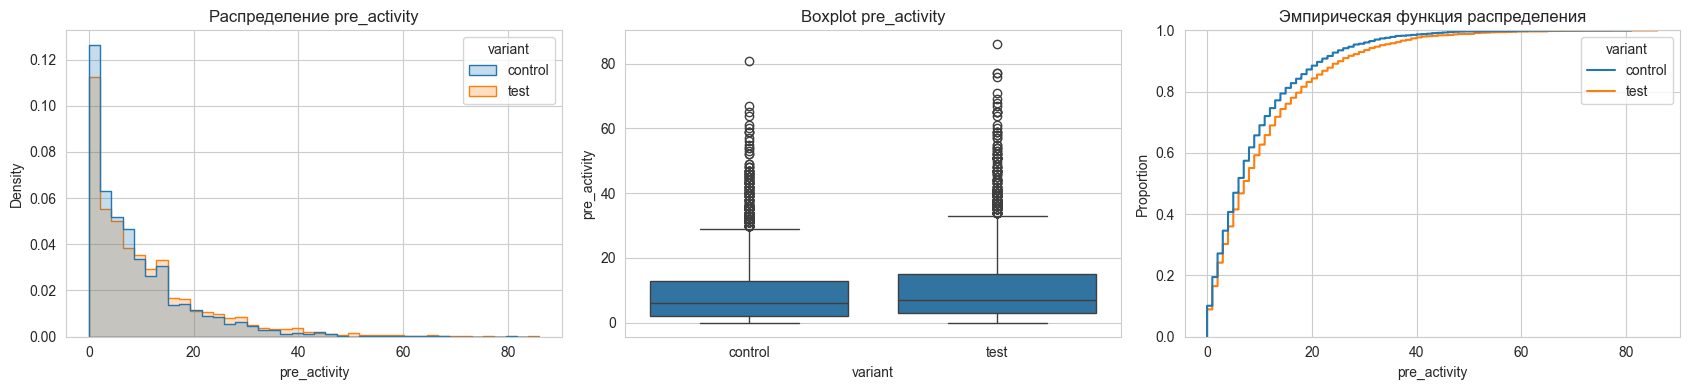

In [8]:
control_pre = df.loc[df['variant'] == 'control', 'pre_activity']
test_pre = df.loc[df['variant'] == 'test', 'pre_activity']

print('Асимметрия pre_activity:', round(df['pre_activity'].skew(), 2))
print('Доля нулей:', round((df['pre_activity'] == 0).mean(), 3))
# тест на нормальность на подвыборке (shapiro не рекомендуют для n > 5000)
print('Shapiro p-value (подвыборка 2000):', stats.shapiro(df['pre_activity'].sample(2000, random_state=1))[1])

fig, axes = plt.subplots(1, 3, figsize=(17, 4))
sns.histplot(data=df, x='pre_activity', hue='variant', stat='density', common_norm=False,
             bins=40, element='step', ax=axes[0])
axes[0].set_title('Распределение pre_activity')
sns.boxplot(data=df, x='variant', y='pre_activity', ax=axes[1])
axes[1].set_title('Boxplot pre_activity')
sns.ecdfplot(data=df, x='pre_activity', hue='variant', ax=axes[2])
axes[2].set_title('Эмпирическая функция распределения')
plt.tight_layout()
plt.show()

In [9]:
u_stat, p_u = stats.mannwhitneyu(test_pre, control_pre, alternative='two-sided')
t_stat, p_t = stats.ttest_ind(test_pre, control_pre, equal_var=False)

print('Среднее pre_activity: control', round(control_pre.mean(), 2), ' test', round(test_pre.mean(), 2))
print('Медиана pre_activity: control', control_pre.median(), ' test', test_pre.median())
print(f'U-тест Манна-Уитни: p-value = {p_u:.2e}')
print(f't-тест Уэлча (для сравнения): p-value = {p_t:.2e}')

if p_u < ALPHA:
    print('ПРЕДУПРЕЖДЕНИЕ: Дисбаланс по pre_activity, возможен confounder')
    warnings_list.append('pre_activity')
else:
    print('Дисбаланса по pre_activity нет')

Среднее pre_activity: control 8.99  test 10.68
Медиана pre_activity: control 6.0  test 7.0
U-тест Манна-Уитни: p-value = 4.63e-11
t-тест Уэлча (для сравнения): p-value = 3.37e-14
ПРЕДУПРЕЖДЕНИЕ: Дисбаланс по pre_activity, возможен confounder


              users  test_share
activity_bin                   
(-1, 2]        2305       0.404
(2, 5]         1673       0.401
(5, 10]        1932       0.423
(10, 20]       1819       0.459
(20, 40]       1033       0.500
(40, 86]        154       0.571


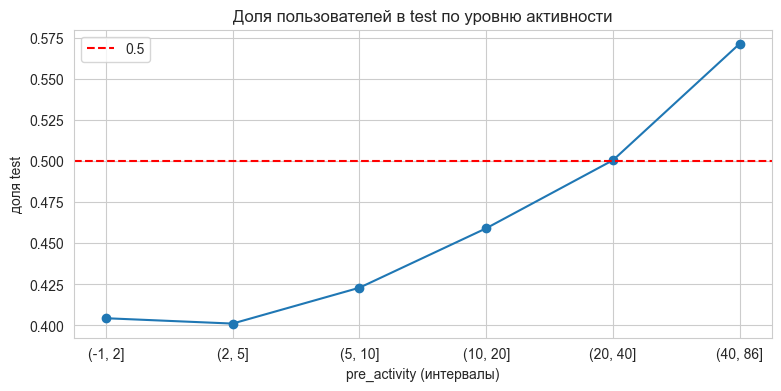

                   coef    std err          z      P>|z|      [0.025      0.975]
--------------------------------------------------------------------------------
const           -0.4283      0.030    -14.371      0.000      -0.487      -0.370
pre_activity     0.0162      0.002      7.675      0.000       0.012       0.020


In [10]:
# доля test в зависимости от активности: при честной рандомизации она везде около 0.5
df['activity_bin'] = pd.cut(df['pre_activity'], bins=[-1, 2, 5, 10, 20, 40, df['pre_activity'].max()])
by_bin = df.groupby('activity_bin', observed=True).agg(
    users=('user_id', 'count'),
    test_share=('variant', lambda s: (s == 'test').mean()),
)
print(by_bin.round(3))

plt.figure(figsize=(9, 4))
plt.plot(by_bin.index.astype(str), by_bin['test_share'], marker='o')
plt.axhline(0.5, color='r', linestyle='--', label='0.5')
plt.xlabel('pre_activity (интервалы)')
plt.ylabel('доля test')
plt.title('Доля пользователей в test по уровню активности')
plt.legend()
plt.show()

# логистическая регрессия: вероятность попасть в test от pre_activity
logit = sm.Logit((df['variant'] == 'test').astype(int), sm.add_constant(df['pre_activity'])).fit(disp=0)
print(logit.summary().tables[1])

**Вывод по балансу `pre_activity`:**

- Распределение `pre_activity` далеко от нормального: сильная правая асимметрия (1.89), почти 10% нулей, тест Шапиро-Уилка отвергает нормальность. Поэтому основной тест U-тест Манна-Уитни.
- В test пользователи активнее: среднее 10.68 против 8.99, медиана 7 против 6. U-тест: p-value около 5e-11, **дисбаланс по `pre_activity` значимый, возможен confounder**. t-тест даёт тот же вывод.
- Доля test растёт вместе с активностью: среди малоактивных (до 5 действий) около 40%, среди самых активных (больше 40 действий) 57%. Логистическая регрессия подтверждает: коэффициент при `pre_activity` положительный (0.016) и значимый (p < 0.001).
- Это нарушение независимости рандомизации: активные пользователи чаще попадают в test. Если активность влияет на конверсию, разница между группами будет частично объясняться не фичей, а составом групп.

## 5. Guardrail-метрика `error_flag`

Считаем частоту ошибок в группах и проверяем различие z-тестом для двух долей.

In [11]:
errors = df.groupby('variant')['error_flag'].agg(['sum', 'count', 'mean'])
errors.columns = ['ошибок', 'пользователей', 'частота']

# доверительные интервалы Уилсона для каждой группы
ci = [proportion_confint(row['ошибок'], row['пользователей'], method='wilson') for _, row in errors.iterrows()]
errors['ДИ низ'] = [c[0] for c in ci]
errors['ДИ верх'] = [c[1] for c in ci]
print(errors.round(4))

z_err, p_err = proportions_ztest(errors['ошибок'].values, errors['пользователей'].values)
ratio = errors.loc['test', 'частота'] / errors.loc['control', 'частота']
print()
print(f'Частота ошибок в test выше в {ratio:.2f} раза')
print(f'z = {z_err:.2f}, p-value = {p_err:.4f}')

if p_err < ALPHA and errors.loc['test', 'частота'] > errors.loc['control', 'частота']:
    print('ПРЕДУПРЕЖДЕНИЕ: guardrail нарушен, ошибок в test значимо больше')
    warnings_list.append('guardrail')
else:
    print('Значимого ухудшения guardrail нет')

         ошибок  пользователей  частота  ДИ низ  ДИ верх
variant                                                 
control    57.0           5056   0.0113  0.0087   0.0146
test       81.0           3860   0.0210  0.0169   0.0260

Частота ошибок в test выше в 1.86 раза
z = -3.68, p-value = 0.0002
ПРЕДУПРЕЖДЕНИЕ: guardrail нарушен, ошибок в test значимо больше


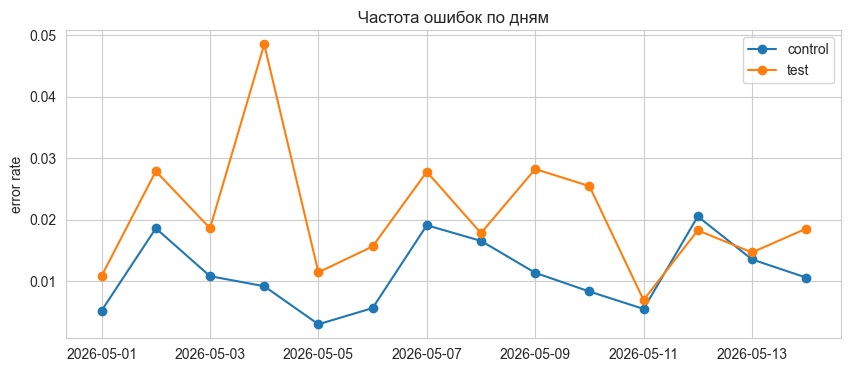

Дней, когда ошибок в test больше, чем в control: 13 из 14


In [12]:
# частота ошибок по дням в каждой группе
daily_err = df.groupby(['date', 'variant'])['error_flag'].mean().unstack()

plt.figure(figsize=(10, 4))
for col in daily_err.columns:
    plt.plot(daily_err.index, daily_err[col], marker='o', label=col)
plt.title('Частота ошибок по дням')
plt.ylabel('error rate')
plt.legend()
plt.show()

print('Дней, когда ошибок в test больше, чем в control:',
      (daily_err['test'] > daily_err['control']).sum(), 'из', len(daily_err))

**Вывод по guardrail:**

- Частота ошибок в control 1.13% (95% ДИ 0.87-1.46%), в test 2.10% (95% ДИ 1.69-2.60%), то есть в test в 1.86 раза выше. Доверительные интервалы не пересекаются.
- z-тест для долей: p-value = 0.0002, **рост ошибок значимый**.
- Это устойчивая картина, а не выброс одного дня: в 13 днях из 14 ошибок в test больше, чем в control.
- Ошибки загрузки страницы связаны с тестовой версией (вряд ли их можно объяснить составом групп), поэтому даже при росте конверсии такую версию выкатывать нельзя.

## 6. Решение о валидности эксперимента

Если есть хотя бы одно предупреждение, эксперимент не валиден. Если всё в порядке, проводим стандартный анализ конверсии.

In [13]:
def analyze_conversion(data, label=''):
    # z-тест для двух долей и доверительный интервал разницы
    conv = data.groupby('variant')['converted'].agg(['sum', 'count', 'mean'])
    z, p = proportions_ztest(conv['sum'].values, conv['count'].values)
    p_c = conv.loc['control', 'mean']
    p_t = conv.loc['test', 'mean']
    diff = p_t - p_c
    se = np.sqrt(p_c * (1 - p_c) / conv.loc['control', 'count'] + p_t * (1 - p_t) / conv.loc['test', 'count'])
    print(label)
    print(f'Конверсия control = {p_c:.4f}, test = {p_t:.4f}')
    print(f'Разница = {diff:.4f}, 95% ДИ [{diff - 1.96 * se:.4f}, {diff + 1.96 * se:.4f}], lift = {diff / p_c * 100:.1f}%')
    print(f'p-value = {p:.4f} ->', 'различие значимо' if p < ALPHA else 'различие не значимо')
    return diff, p


print('Найденные предупреждения:', warnings_list)
print()
if len(warnings_list) > 0:
    print('Эксперимент не валиден.')
    print('Остановить тест, исправить ошибки, перезапустить')
else:
    analyze_conversion(df, 'Стандартный анализ конверсии')

Найденные предупреждения: ['SRM', 'pre_activity', 'guardrail']

Эксперимент не валиден.
Остановить тест, исправить ошибки, перезапустить


In [14]:
# только для иллюстрации: что показал бы наивный анализ конверсии без проверок
_ = analyze_conversion(df, 'Наивный анализ (на невалидных данных, делать выводы по нему нельзя)')

Наивный анализ (на невалидных данных, делать выводы по нему нельзя)
Конверсия control = 0.0481, test = 0.0528
Разница = 0.0048, 95% ДИ [-0.0044, 0.0140], lift = 10.0%
p-value = 0.3046 -> различие не значимо


**Решение:** найдено три предупреждения (SRM, дисбаланс по `pre_activity`, нарушенный guardrail), поэтому **эксперимент не валиден: остановить тест, исправить ошибки, перезапустить**.

Наивный анализ конверсии приведён только для иллюстрации: конверсия в test 5.28% против 4.81% в control, lift +10%, но p-value = 0.30 и ДИ разницы [-0.44; +1.40] п.п. включает ноль. Даже этот результат нельзя использовать для решения, потому что группы несопоставимы.

## 7. Дополнительные проверки

Проверим, связана ли конверсия с `pre_activity` (тогда дисбаланс по активности действительно может исказить результат), и нет ли временных трендов.

In [15]:
# конверсия по уровню активности в каждой группе
conv_bin = df.groupby(['activity_bin', 'variant'], observed=True)['converted'].mean().unstack()
print(conv_bin.round(4))

r, p_r = stats.pointbiserialr(df['converted'], df['pre_activity'])
print()
print(f'Корреляция converted и pre_activity: r = {r:.3f}, p-value = {p_r:.4f}')

# логистическая регрессия конверсии на группу и активность
X_conv = pd.DataFrame({
    'const': 1.0,
    'test': (df['variant'] == 'test').astype(int),
    'pre_activity': df['pre_activity'],
})
logit_conv = sm.Logit(df['converted'], X_conv).fit(disp=0)
print(logit_conv.summary().tables[1])

variant       control    test
activity_bin                 
(-1, 2]        0.0488  0.0601
(2, 5]         0.0449  0.0373
(5, 10]        0.0395  0.0551
(10, 20]       0.0569  0.0479
(20, 40]       0.0484  0.0600
(40, 86]       0.0909  0.0795

Корреляция converted и pre_activity: r = 0.013, p-value = 0.2099
                   coef    std err          z      P>|z|      [0.025      0.975]
--------------------------------------------------------------------------------
const           -3.0350      0.079    -38.659      0.000      -3.189      -2.881
test             0.0906      0.098      0.926      0.354      -0.101       0.282
pre_activity     0.0053      0.005      1.169      0.242      -0.004       0.014


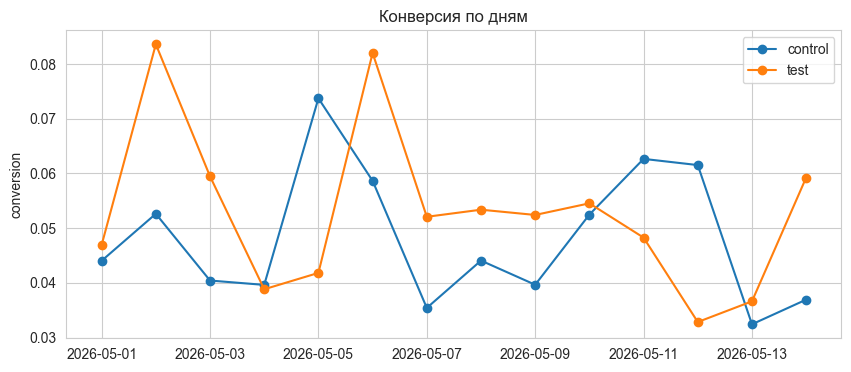

In [16]:
# конверсия по дням
daily_conv = df.groupby(['date', 'variant'])['converted'].mean().unstack()

plt.figure(figsize=(10, 4))
for col in daily_conv.columns:
    plt.plot(daily_conv.index, daily_conv[col], marker='o', label=col)
plt.title('Конверсия по дням')
plt.ylabel('conversion')
plt.legend()
plt.show()

**Вывод:**

- В этих данных конверсия слабо связана с `pre_activity`: корреляция 0.013 (p = 0.21), в логистической регрессии коэффициент активности тоже незначимый. По коду генерации вероятность конверсии растёт с активностью всего с 5% до 6%, поэтому эффект маленький и на нашей выборке статистически не виден.
- В логистической регрессии с `pre_activity` коэффициент группы test незначимый (p = 0.35), как и в наивном анализе.
- Конверсия по дням колеблется вокруг 4-6% в обеих группах без явного тренда, группы то и дело меняются местами. Временных аномалий нет.

## 8. Бонус: исправление дисбаланса по `pre_activity`

SRM и рост ошибок данными не исправить: это признак сломанной рандомизации и бага в тестовой версии. А вот дисбаланс по `pre_activity` можно скорректировать статистически. Попробуем два способа:
1. **Взвешивание по обратной вероятности (IPW):** оцениваем вероятность попасть в test в зависимости от `pre_activity` (propensity score) и взвешиваем пользователей так, чтобы группы стали сопоставимы.
2. **Стратификация:** сравниваем конверсию внутри слоёв по `pre_activity` и усредняем разницу с весами слоёв.

In [17]:
# 1. IPW: propensity score через логистическую регрессию
df['is_test'] = (df['variant'] == 'test').astype(int)
ps_model = sm.Logit(df['is_test'], sm.add_constant(df['pre_activity'])).fit(disp=0)
df['ps'] = ps_model.predict(sm.add_constant(df['pre_activity']))

# веса: 1 / ps для test и 1 / (1 - ps) для control
df['w'] = np.where(df['is_test'] == 1, 1 / df['ps'], 1 / (1 - df['ps']))

print('Propensity score: min', round(df['ps'].min(), 3), ' max', round(df['ps'].max(), 3))


def weighted_mean(x, w):
    return np.sum(x * w) / np.sum(w)


# баланс pre_activity до и после взвешивания
balance = pd.DataFrame({
    'до взвешивания': df.groupby('variant')['pre_activity'].mean(),
    'после IPW': df.groupby('variant').apply(lambda g: weighted_mean(g['pre_activity'], g['w'])),
})
print()
print('Среднее pre_activity по группам:')
print(balance.round(3))

Propensity score: min

 0.395  max 0.724



Среднее pre_activity по группам:
         до взвешивания  после IPW
variant                           
control           8.990      9.706
test             10.676      9.712


In [18]:
# эффект на конверсию после IPW, доверительный интервал через бутстрап
def ipw_effect(data):
    t = data[data['is_test'] == 1]
    c = data[data['is_test'] == 0]
    return weighted_mean(t['converted'], t['w']) - weighted_mean(c['converted'], c['w'])


ipw_diff = ipw_effect(df)

rng = np.random.default_rng(42)
boot = []
for _ in range(1000):
    sample = df.iloc[rng.integers(0, len(df), len(df))]
    boot.append(ipw_effect(sample))
ci_low, ci_high = np.percentile(boot, [2.5, 97.5])

naive_diff = df.loc[df['is_test'] == 1, 'converted'].mean() - df.loc[df['is_test'] == 0, 'converted'].mean()
print(f'Наивная разница конверсий: {naive_diff:.4f}')
print(f'Разница после IPW: {ipw_diff:.4f}, 95% бутстрап-ДИ [{ci_low:.4f}, {ci_high:.4f}]')
print('Ноль внутри ДИ:', ci_low <= 0 <= ci_high)

Наивная разница конверсий: 0.0048
Разница после IPW: 0.0044, 95% бутстрап-ДИ [-0.0042, 0.0134]
Ноль внутри ДИ: True


In [19]:
# 2. стратификация по квантилям pre_activity
df['stratum'] = pd.qcut(df['pre_activity'], q=5, duplicates='drop')

strata = df.groupby(['stratum', 'variant'], observed=True)['converted'].agg(['mean', 'count']).unstack()
strata['diff'] = strata[('mean', 'test')] - strata[('mean', 'control')]
strata['weight'] = (strata[('count', 'test')] + strata[('count', 'control')]) / len(df)
strata['var'] = (strata[('mean', 'test')] * (1 - strata[('mean', 'test')]) / strata[('count', 'test')]
                 + strata[('mean', 'control')] * (1 - strata[('mean', 'control')]) / strata[('count', 'control')])
print(strata.round(4))

strat_diff = (strata['diff'] * strata['weight']).sum()
strat_se = np.sqrt((strata['weight'] ** 2 * strata['var']).sum())
print()
print(f'Стратифицированная разница: {strat_diff:.4f}, 95% ДИ [{strat_diff - 1.96 * strat_se:.4f}, {strat_diff + 1.96 * strat_se:.4f}]')

                 mean           count         diff  weight     var
variant       control    test control test                        
stratum                                                           
(-0.001, 2.0]  0.0488  0.0601    1373  932  0.0113  0.2585  0.0001
(2.0, 5.0]     0.0449  0.0373    1002  671 -0.0077  0.1876  0.0001
(5.0, 9.0]     0.0401  0.0512     948  683  0.0112  0.1829  0.0001
(9.0, 16.0]    0.0499  0.0524     862  725  0.0025  0.1780  0.0001
(16.0, 86.0]   0.0574  0.0589     871  849  0.0015  0.1929  0.0001

Стратифицированная разница: 0.0043, 95% ДИ [-0.0050, 0.0135]


In [20]:
# регрессионная корректировка: логистическая регрессия с ковариатой (из раздела 7)
coef_test = logit_conv.params['test']
p_test = logit_conv.pvalues['test']
print(f'Коэффициент группы test в регрессии с pre_activity: {coef_test:.3f} (p-value = {p_test:.4f})')

# сводка
result = pd.DataFrame({
    'оценка разницы': [naive_diff, ipw_diff, strat_diff],
}, index=['наивная', 'IPW', 'стратификация'])
result.round(4)

Коэффициент группы test в регрессии с pre_activity: 0.091 (p-value = 0.3544)


,оценка разницы
наивная,0.0048
IPW,0.0044
стратификация,0.0043


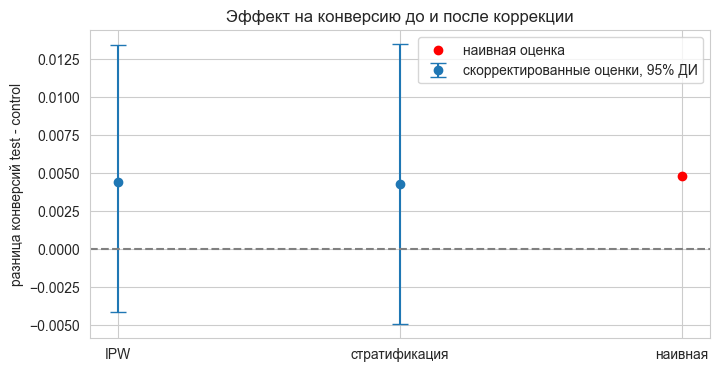

In [21]:
# сравнение оценок на графике
plt.figure(figsize=(8, 4))
plt.errorbar(x=['IPW', 'стратификация'], y=[ipw_diff, strat_diff],
             yerr=[[ipw_diff - ci_low, 1.96 * strat_se], [ci_high - ipw_diff, 1.96 * strat_se]],
             fmt='o', capsize=6, label='скорректированные оценки, 95% ДИ')
plt.scatter(['наивная'], [naive_diff], color='r', label='наивная оценка')
plt.axhline(0, color='gray', linestyle='--')
plt.ylabel('разница конверсий test - control')
plt.title('Эффект на конверсию до и после коррекции')
plt.legend()
plt.show()

**Вывод по коррекции:**

- После IPW-взвешивания средние `pre_activity` в группах выровнялись (9.71 и 9.71 вместо 8.99 и 10.68), то есть дисбаланс по ковариате устранён.
- Оценки эффекта на конверсию после коррекции: IPW +0.44 п.п. (95% бутстрап-ДИ от -0.42 до +1.34 п.п.), стратификация по квинтилям активности +0.43 п.п. (ДИ от -0.50 до +1.35 п.п.). Наивная оценка была +0.48 п.п.
- Коррекция немного уменьшила оценку, как и ожидалось (в test были более активные пользователи, которые чуть чаще конвертируются), но изменение небольшое, потому что связь конверсии с активностью в данных слабая. Во всех вариантах ноль внутри доверительного интервала: эффекта на конверсию нет, что совпадает с истинным дизайном (эффект равен нулю).
- Важно: коррекция исправляет только дисбаланс по известной ковариате. SRM говорит о том, что сломан сам механизм рандомизации, и могут быть перекошены и другие, ненаблюдаемые характеристики пользователей. А рост ошибок это проблема продукта, которую статистикой не исправить. Поэтому скорректированные оценки годятся только как ориентир, а не как основание для запуска.

## Итоговый вывод

**Найденные проблемы:**

| Проблема | Как обнаружена | Результат |
| --- | --- | --- |
| SRM | хи-квадрат, ожидаемое 50/50 | 56.7% / 43.3%, p около 1e-36 |
| Confounder (рандомизация зависит от `pre_activity`) | U-тест, доля test по уровням активности, логистическая регрессия | test активнее (среднее 10.7 против 9.0), p около 5e-11 |
| Нарушение guardrail | z-тест долей | ошибки 2.10% против 1.13% (в 1.86 раза), p = 0.0002 |

**Решение:** эксперимент не валиден. Остановить тест, исправить ошибки, перезапустить.

**Что исправить перед перезапуском:**
1. **Рандомизация.** Назначать группу детерминированно и независимо от характеристик пользователя, например по хэшу `user_id` с солью эксперимента (`hash(user_id + salt) % 100 < 50`). Не использовать при назначении активность и другие признаки.
2. **SRM-мониторинг.** Проверять SRM ежедневно с самого начала (лучше на A/A-тесте до запуска) и останавливать тест при p-value < 0.001.
3. **Ошибки.** Найти причину ошибок загрузки в тестовой версии, исправить и проверить guardrail до старта нового теста. Можно задать порог автоматической остановки по `error_flag`.
4. **Ковариаты.** Перед запуском проверять баланс по `pre_activity` и другим доэкспериментальным признакам. В анализе можно использовать `pre_activity` для снижения дисперсии (CUPED или регрессионная корректировка), но не для назначения групп.
5. **Размер выборки.** Заранее посчитать нужный размер под MDE по конверсии (базовая конверсия около 5%, поэтому для обнаружения небольших эффектов понадобится выборка больше текущей).

По текущим данным, даже после коррекции дисбаланса, значимого эффекта на конверсию нет (около +0.4 п.п., ДИ включает ноль), а guardrail ухудшился. Запускать фичу в таком виде нельзя.